# Mapping migration

## Set up

To get started on this notebook, you’ll need to restore any variables from previous notebooks to your workspace. To save time and memory, make sure to specify which variables you want to load.

In [5]:
%store -r

Unable to restore variable 'gbif_ecoregion_gdf', ignoring (use %store -d to forget!)
The error was: <class 'KeyError'>
Unable to restore variable 'elpaso_Temp_F', ignoring (use %store -d to forget!)
The error was: <class 'KeyError'>
Unable to restore variable 'elpaso_df', ignoring (use %store -d to forget!)
The error was: <class 'KeyError'>
Unable to restore variable 'plot_yearly_avg', ignoring (use %store -d to forget!)
The error was: <class 'KeyError'>


You will also need to import any libraries you are using in this notebook:

In [6]:
### import libraries
import os 
import pathlib
import geopandas as gpd
import pandas as pd 
import earthpy as et
import hvplot.pandas

## Connect the GBIF observations to the ecoregions

### Identify the ecoregion for each observation

You can combine the ecoregions and the observations **spatially** using a method called `.sjoin()`, which stands for spatial join.

Check out the [`geopandas` documentation on spatial joins](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html#spatial-joins) to learn more about spatial joins and how they work.

To perform your spatial join, you'll need to identify the correct values for the `how =` and `predicate =` parameters of the spatial join.

In [7]:
gbif_gdf_geese.head()

,month,geometry
gbifID,,
4112572331,5.0,POINT (19.91819 60.11294)
4126553401,6.0,POINT (26.14848 61.31082)
4112577303,5.0,POINT (19.92421 60.11542)
4135109425,6.0,POINT (26.72213 61.39444)
4135102409,6.0,POINT (26.72581 61.39337)


In [9]:
### join the gbif observations to the ecoregion polygons
geese_eco_gdf = (
    gdf

    
    ### match the CRS of the gbif data and the ecoregions
    .to_crs(gbif_gdf.crs)

    ### find ecoregion for each observation
    .sjoin(
        gbif_gdf_geese,
        how = 'inner', #type of join to perform
        predicate = 'contains') 

    ### specify what columns you want to join 
    ### rename your OBJECTID column to ecoregion for another join later on 

    [['OBJECTID', 'month']]

    .rename(columns= {
        'OBJECTID': 'ecoregion',
    })
)

### check it out
geese_eco_gdf

,ecoregion,month
4,5.0,5.0
9,10.0,4.0
9,10.0,6.0
9,10.0,6.0
9,10.0,6.0
...,...,...
839,845.0,5.0
839,845.0,4.0
839,845.0,3.0
839,845.0,6.0


### Count the observations in each ecoregion each month

First, group the GBIF observations by ecoregion:
1. Replace `columns_to_group_by` with a list of columns. Keep in mind that you will end up with one row for each group – you want to count the observations in each ecoregion by month.
2. Select only month/ecoregion combinations that have more than one occurrence recorded, since a single occurrence could be an error.
3. Use the `.groupby()` and `.mean()` methods to compute the mean occurrences by ecoregion and by month.
4. Run the code – it will normalize the number of occurrences by month and ecoregion.

In [15]:
### summarize the occurrences by ecoregion/month combination
occurrence_df = (
    geese_eco_gdf

    ### group by each ecoregion and month 
    .groupby(['ecoregion', 'month'])

    ### and count the number of occurrences
    .agg(occurrences=('ecoregion', 'count'))
)

### get rid of rare observations (which are possibly misidentifications)
occurrence_df = occurrence_df[occurrence_df.occurrences > 5]

### calculate the mean # observations by ecoregion
mean_occurrences_by_ecoregion = (
    occurrence_df
    .groupby('ecoregion')
    .mean()
    
)

### calculate the mean # observations by month
mean_occurrences_by_month = (
    occurrence_df
    .groupby('month')
    .mean()
)

### Normalize the observations

Divide occurrences by the mean occurrences by month and by ecoregion.

In [16]:
### normalize by space and time for sampling effort
occurrence_df['norm_occurrences'] = (
    occurrence_df
    / mean_occurrences_by_ecoregion
    / mean_occurrences_by_month
)
### check it out
occurrence_df

occurrences  norm_occurrences
ecoregion month                               
10.0      6.0             24          0.000844
11.0      1.0             10          0.000318
          3.0             13          0.000312
          4.0             27          0.000482
          5.0             16          0.000285
...                      ...               ...
845.0     6.0             31          0.000991
          7.0             11          0.000377
          8.0             27          0.000850
          9.0              6          0.000138
          10.0            15          0.000320

[1207 rows x 2 columns]

### Lets make a few plot to visualize our data

<Axes: xlabel='Normalized Occurences of Canadia Goose Population', ylabel='Frequency'>

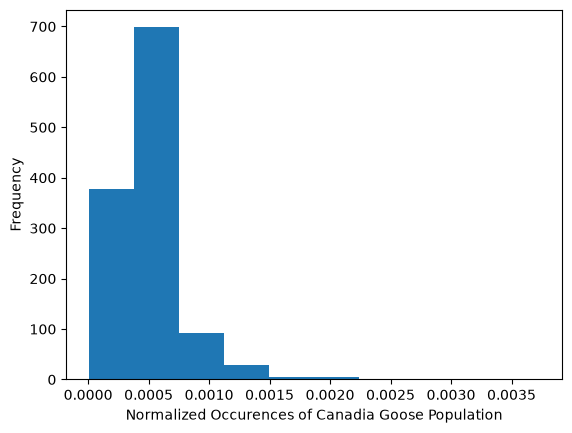

In [17]:
### histogram of normalized occurrences
occurrence_df.norm_occurrences.plot.hist(
    x = 'norm_occurences',
    xlabel = 'Normalized Occurences of Canadia Goose Population',
)

Given this is now normalized data, the values seem to be quite low, lets look at a different plot to start to examine our data, and its trends

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
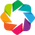

In [18]:
### import holoviews for our next plot
import holoviews as hv
hv.extension("bokeh")

In [22]:
### lets make a line plot to help understand seasonal patterns of migration
top_ecoregions = (
    occurrence_df.groupby('ecoregion').occurrences.sum() # groupby occurences and count the sum of occurences per ecoregion
    .nlargest(10).index # keep only the ecoregions with a lot of occurences (top 10)
)
plot_df = occurrence_df.reset_index() 
plot_df = plot_df[plot_df.ecoregion.isin(top_ecoregions)]  #keep only the rows whose ecoregion is top 10 for the plot
plot_df

### create the line plot 
line_plot = plot_df.hvplot.line(
    x = 'month', # x-axis
    y = 'norm_occurrences', # y-axis
    by = 'ecoregion', # draw a line per ecoregion
    xlabel = 'Month',
    ylabel = 'Normalized occurrences',
    title = "Candadian Goose Migration Trend by Ecoregion",
    ### plot dimensions 
    width = 900, 
    height = 500,
    legend = 'right', #location of legend
)
### save the figure as an html
hv.save(
    line_plot,
    os.path.join(data_dir, "Canadiangoose_migration_trend.html"),
    fmt = 'html',
)
line_plot

:NdOverlay   [ecoregion]
   :Curve   [month]   (norm_occurrences)

This plot does well to show that some Canadian Goose populations are year round residents, while others exhibit migratory patterns, lets map this in our next notebook for a visualization of these trends on a basemap for more context.

# Store Vars

In [20]:
%store occurrence_df

Stored 'occurrence_df' (DataFrame)
